### Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV, RidgeCV, LinearRegression
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline

### Load Data

In [5]:
# Case 1
df_train1 = pd.read_csv('../data/case1/train1.csv')
df_test1 = pd.read_csv('../data/case1/train1.csv')

##### Making operating state binary

In [7]:
mapping = {
    "stable": 0,
    "transient": 1
}

df_train1['operating_state'] = df_train1['operating_state'].map(mapping)

df_train1

,pump_id,elapsed_s,operating_state,speed_rpm,power_w,inlet_pressure_bar,outlet_pressure_bar,flow_m3_h
0,99223468_model_01,14.5,0,4230.396017,669.992714,1.057136,2.414427,0.652884
1,99223468_model_01,24.5,0,3796.519900,931.528480,2.097392,2.390436,43.040564
2,99223468_model_01,34.5,0,3508.264375,724.198083,2.247896,2.433662,40.939560
3,99223468_model_01,44.5,0,1498.405243,99.463217,2.287246,2.451128,11.857951
4,99223468_model_01,64.5,0,3224.873653,608.195308,2.464618,2.696299,36.000996
...,...,...,...,...,...,...,...,...
475,99223468_model_01,5944.5,0,4376.002303,815.229829,1.016499,2.478924,3.032111
476,99223468_model_01,5964.5,0,3514.587072,515.961500,1.411002,2.338274,5.566221
477,99223468_model_01,5974.5,0,2935.129740,534.173942,2.178489,2.678476,22.873572
478,99223468_model_01,5984.5,0,2214.152995,154.677482,2.032066,2.410823,3.776250


## TASK 0
### Subtask 1
#### Create relevant new feature columns by combining existing features.

In [6]:
### new features

# speed in krpm, n
df_train1['krpm'] = df_train1['speed_rpm'] / 1000

# pressure rise across pump
df_train1['delta_p'] = (
    df_train1['outlet_pressure_bar'] - df_train1['inlet_pressure_bar']
)

df_train1['n2'] = df_train1['krpm']**2
df_train1['n3'] = df_train1['krpm']**3

df_train1['Q2'] = df_train1['flow_m3_h']**2
df_train1['Q3'] = df_train1['flow_m3_h']**3

df_train1['nQ'] = df_train1['krpm'] * df_train1['flow_m3_h']
df_train1['nQ2'] = df_train1['krpm'] * df_train1['flow_m3_h']**2
df_train1['nQ3'] = df_train1['krpm'] * df_train1['Q3']

df_train1['n2Q'] = df_train1['krpm']**2 * df_train1['flow_m3_h']
df_train1['n2Q2'] = df_train1['n2'] * df_train1['Q2']
df_train1['n2Q3'] = df_train1['n2'] * df_train1['Q3']

df_train1['n3Q'] = df_train1['flow_m3_h'] * df_train1['n3']
df_train1['n3Q2'] = df_train1['n3'] * df_train1['Q2']
df_train1['n3Q3'] = df_train1['n3'] * df_train1['Q3']

In [9]:
df_train1

,pump_id,elapsed_s,operating_state,speed_rpm,power_w,inlet_pressure_bar,outlet_pressure_bar,flow_m3_h,krpm,delta_p,...,Q3,nQ,nQ2,nQ3,n2Q,n2Q2,n2Q3,n3Q,n3Q2,n3Q3
0,99223468_model_01,14.5,stable,4230.396017,669.992714,1.057136,2.414427,0.652884,4.230396,1.357291,...,0.278296,2.761956,1.803236,1.177303,11.684169,7.628402,4.980459e+00,49.428660,32.271162,2.106931e+01
1,99223468_model_01,24.5,stable,3796.519900,931.528480,2.097392,2.390436,43.040564,3.796520,0.293043,...,79732.222413,163.404359,7033.015810,302704.969059,620.367900,26700.984478,1.149225e+06,2355.239078,101370.818919,4.363057e+06
2,99223468_model_01,34.5,stable,3508.264375,724.198083,2.247896,2.433662,40.939560,3.508264,0.185766,...,68616.648822,143.626799,5880.017914,240725.344589,503.880782,20628.657370,8.445282e+05,1767.746997,72370.783753,2.962828e+06
3,99223468_model_01,44.5,stable,1498.405243,99.463217,2.287246,2.451128,11.857951,1.498405,0.163881,...,1667.358317,17.768016,210.692258,2498.378443,26.623688,315.702384,3.743583e+03,39.893074,473.050107,5.609405e+03
4,99223468_model_01,64.5,stable,3224.873653,608.195308,2.464618,2.696299,36.000996,3.224874,0.231682,...,46659.871276,116.098662,4179.667444,150472.189541,374.403518,13478.899418,4.852538e+05,1207.404040,43467.747606,1.564882e+06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
475,99223468_model_01,5944.5,stable,4376.002303,815.229829,1.016499,2.478924,3.032111,4.376002,1.462426,...,27.876314,13.268525,40.231643,121.986814,58.063097,176.053764,5.338146e+02,254.084248,770.411677,2.335974e+03
476,99223468_model_01,5964.5,stable,3514.587072,515.961500,1.411002,2.338274,5.566221,3.514587,0.927272,...,172.457177,19.562967,108.891795,606.115765,68.755752,382.709694,2.130247e+03,241.648078,1345.066544,7.486937e+03
477,99223468_model_01,5974.5,stable,2935.129740,534.173942,2.178489,2.678476,22.873572,2.935130,0.499988,...,11967.459519,67.136901,1535.660738,35126.046346,197.055515,4507.363504,1.030995e+05,578.383504,13229.696669,3.026104e+05
478,99223468_model_01,5984.5,stable,2214.152995,154.677482,2.032066,2.410823,3.776250,2.214153,0.378757,...,53.849573,8.361196,31.573966,119.231193,18.512966,69.909591,2.639961e+02,40.990539,154.790530,5.845278e+02


##### Defining X and y

In [10]:
exclude_cols = [
    'pump_id',
    'speed_rpm',
    'elapsed_s',
    'operating_state',
    'power_w',
    'inlet_pressure_bar',
    'outlet_pressure_bar',
    'delta_p'
]

X = df_train1.drop(columns=exclude_cols)
y = df_train1['power_w']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


### Subtask 2
#### Fit Linear Regression models with relevant new and old feature columns.

In [11]:
model_0 = LinearRegression()
model_0.fit(X_train, y_train)
y_0_pred = model_0.predict(X_test)


r2_model_0 = round(model_0.score(X_train, y_train) , 5)
print(f"R^2 for model 0 is {r2_model_0}")

mse_model_0 = round(mean_squared_error(y_true = y_test, y_pred = y_0_pred) , 5)
print(f"MSE for model 0 is {mse_model_0}")

R^2 for model 0 is 0.99968
MSE for model 0 is 135.89109


### Subtask 3
#### Apply feature selection method to find polynomial of form $P$ that matches the data best.
##### Lasso

In [12]:
lasso_0 = Pipeline([
    ('scaler', StandardScaler()),
    ('lasso', LassoCV(cv=5))
])
lasso_0.fit(X_train, y_train)
lasso_model = lasso_0.named_steps['lasso']


sel_features_las = X_train.columns[lasso_model.coef_ != 0]
best_alp_las = round(lasso_model.alpha_ , 5)
print(f"The selected features are {sel_features_las} \nBest alpha is {best_alp_las}")

model_0_lasso = LinearRegression()

X_train_lasso = X_train[sel_features_las]
X_test_lasso = X_test[sel_features_las]
model_0_lasso.fit(X_train_lasso, y_train)
y_pred_las = model_0_lasso.predict(X_test_lasso)

# Print coefficients
coef_df = pd.DataFrame({
    'Feature': X_train_lasso.columns,
    'Coefficient': model_0_lasso.coef_
})

print("\nRegression Coefficients:")
print(coef_df)

print(f"\nIntercept: {model_0_lasso.intercept_:.4f}")

equation = f"y = {model_0_lasso.intercept_:.4f}"

for feature, coef in zip(X_train_lasso.columns, model_0_lasso.coef_):
    sign = "+" if coef >= 0 else "-"
    equation += f" {sign} {abs(coef):.4f}*{feature}"

print("\nRegression Equation:")
print(equation)

y_pred_las = model_0_lasso.predict(X_test_lasso)


r2_lasso = round(r2_score(y_test, y_pred_las) , 5)
print(f"R^2 for model 0 using lasso is {r2_lasso}")

mse_lasso = round(mean_squared_error(y_true = y_test, y_pred = y_pred_las) , 5)
print(f"MSE for model 0 using lasso is {mse_lasso}")

The selected features are Index(['krpm', 'n2', 'n3', 'Q3', 'nQ', 'n2Q', 'n2Q3', 'n3Q', 'n3Q3'], dtype='object') 
Best alpha is 0.51822

Regression Coefficients:
  Feature  Coefficient
0    krpm    22.379690
1      n2    -7.056988
2      n3     8.591556
3      Q3    -0.010118
4      nQ    -0.506837
5     n2Q     2.383554
6    n2Q3    -0.000155
7     n3Q    -0.025253
8    n3Q3     0.000025

Intercept: 20.8751

Regression Equation:
y = 20.8751 + 22.3797*krpm - 7.0570*n2 + 8.5916*n3 - 0.0101*Q3 - 0.5068*nQ + 2.3836*n2Q - 0.0002*n2Q3 - 0.0253*n3Q + 0.0000*n3Q3
R^2 for model 0 using lasso is 0.99952
MSE for model 0 using lasso is 159.86778


/opt/anaconda3/envs/ml/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.960e+04, tolerance: 1.147e+04
  model = cd_fast.enet_coordinate_descent(


### Subtask 4
#### Report your final regression expression and your test errors, using one or more informative error measures of your choice, and show a plot of errors versus flow.

Final reg: $P = 31.3534 + 1.7682*n^2 + 7.3905*n^3 - 0.1956*Q^2 - 0.0049*Q^3 + 2.3700*nQ + 1.3508*n^2Q - 0.0008*nQ^3 + 0.1110*n^3Q$

##### Lasso

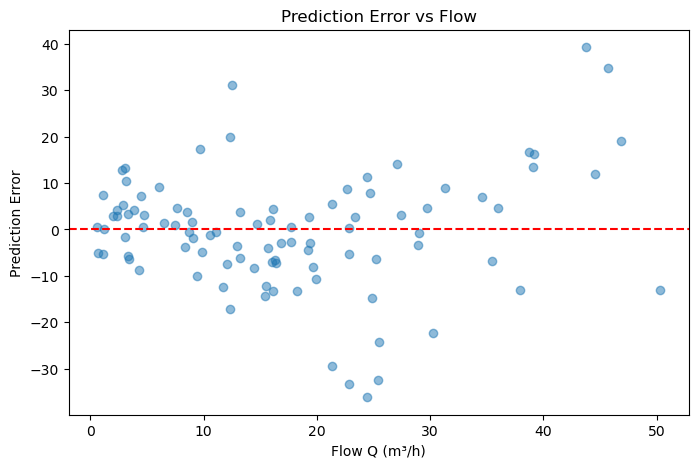

In [13]:
errors = y_pred_las - y_test

plt.figure(figsize=(8,5))
plt.scatter(X_test['flow_m3_h'], errors, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Flow Q (m³/h)')
plt.ylabel('Prediction Error')      # Predicted P - True P)
plt.title('Prediction Error vs Flow')
plt.show()

#### Forward Feature Selection

In [14]:
forward = SequentialFeatureSelector(
    model_0,
    n_features_to_select = 'auto',
    direction = 'forward',
    cv=5
)

forward.fit(X_train, y_train)

selected_features = X_train.columns[forward.get_support()]
print(f"The selected features are: {selected_features}")

X_train_forward = X_train[selected_features]
X_test_forward = X_test[selected_features]

model_0_forward = LinearRegression()

model_0_forward.fit(X_train_forward, y_train)

y_pred_forward = model_0_forward.predict(X_test_forward)

r2_forward = round(r2_score(y_test, y_pred_forward) , 5)
print(f"R^2 for model 0 using Forward Elimination is {r2_forward}")

mse_forward = round(mean_squared_error(y_true = y_test, y_pred = y_pred_forward) , 3)
print(f"MSE for model 0 using lasso is {mse_forward}")

The selected features are: Index(['flow_m3_h', 'krpm', 'n2', 'n3', 'Q3', 'nQ2', 'n2Q'], dtype='object')
R^2 for model 0 using Forward Elimination is 0.99959
MSE for model 0 using lasso is 134.846


#### Backward Feature Elimination

In [15]:
backward = SequentialFeatureSelector(
    model_0,
    n_features_to_select = 'auto',
    direction = 'backward',
    cv=5
)

backward.fit(X_train, y_train)

selected_features = X_train.columns[backward.get_support()]
print(f"The selected features are: {selected_features}")

X_train_backward = X_train[selected_features]
X_test_backward = X_test[selected_features]

model_0_backward = LinearRegression()

model_0_backward.fit(X_train_backward, y_train)

y_pred_backward = model_0_backward.predict(X_test_backward)

r2_backward = round(r2_score(y_test, y_pred_backward) , 5)
print(f"R^2 for model 0 using Forward Elimination is {r2_backward}")

mse_backward = round(mean_squared_error(y_true = y_test, y_pred = y_pred_backward) , 3)
print(f"MSE for model 0 using lasso is {mse_backward}")

The selected features are: Index(['n3', 'Q2', 'Q3', 'nQ2', 'nQ3', 'n2Q', 'n2Q3', 'n3Q3'], dtype='object')
R^2 for model 0 using Forward Elimination is 0.99959
MSE for model 0 using lasso is 135.768
